# 7. Partial Differential Equations: Exercise

Name: Xiuning Zhang

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from scipy.integrate import odeint

## 1. Diffusion Equation
For the diffusion equation with Dirichlet boundary condition, take initial states with different spatial frequencyes, such as

$$ y(x, 0) = \sin(\frac{nx}{L}\pi ) $$

with different $n$, and see how quickly they decay in time.

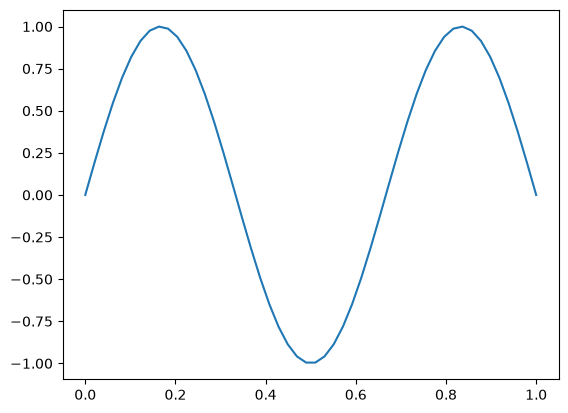

In [2]:
L = 1
x = np.linspace(0, L)
n = 3
y = np.sin(n*x*np.pi/L)
plt.plot(x, y)

In [3]:
def diff1D(y, t, x, D, inp=None):
    """1D Diffusion equaiton with constant boundary condition
    y: state vector
    t: time
    x: positions
    D: diffusion coefficient
    input: function(y,x,t)"""
    dx = x[1] - x[0]  # space step
    # shift to left and right and subtract, with both ends cut
    d2ydx2 = (y[:-2] -2*y[1:-1] + y[2:])/dx**2
    # add 0 to both ends for Dirichlet boundary condition
    d2ydx2 = np.hstack((0, d2ydx2, 0))
    if inp == None:
        return D*d2ydx2
    else:
        return D*d2ydx2 + inp(y, x, t)

In [4]:
def euler(f, y0, dt, n, args=()):
    """f: righthand side of ODE dy/dt=f(y,t)
        y0: initial condition y(0)=y0
        dt: time step
        n: iteratons
        args: parameter for f(y,t,*args)"""
    d = np.array([y0]).size  ## state dimension
    y = np.zeros((n+1, d))
    y[0] = y0
    t = 0
    for k in range(n):
        y[k+1] = y[k] + f(y[k], t, *args)*dt
        t = t + dt
    return y

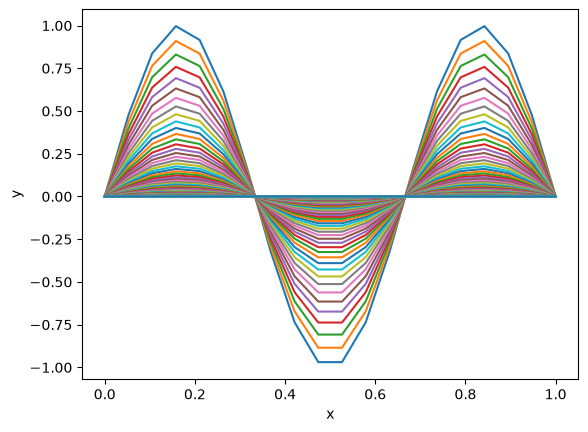

In [23]:
L = 1
N = 20
x = np.linspace(0, L, N)
n = 3
y0 = np.sin(n*x*np.pi/L)
D = 0.1  # diffusion constant
dt = 0.01 # time step
ts = 1.   # time for solution
y = euler(diff1D, y0, dt, int(ts/dt), (x, D))
# spatial pattern at different time
plt.plot(x, y.T)
plt.xlabel("x"); plt.ylabel("y");

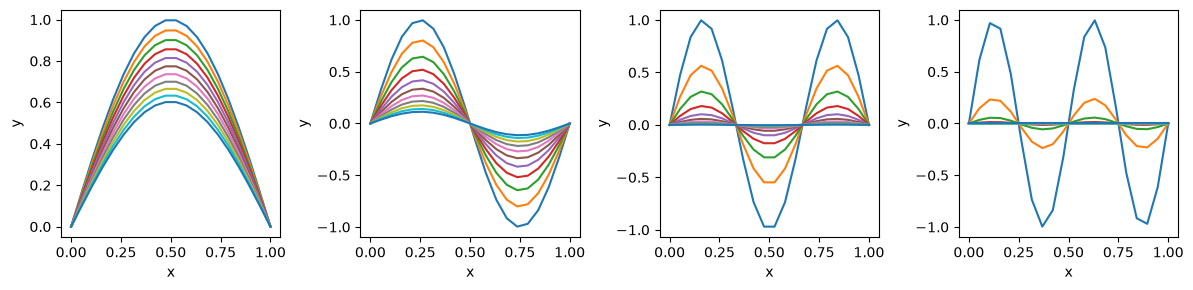

In [29]:
fig, ax = plt.subplots(1, 4, figsize=(12, 3))
for i, n in enumerate([1, 2, 3, 4]):
    L = 1
    N = 20
    x = np.linspace(0, L, N)
    y0 = np.sin(n*x*np.pi/L)
    D = 0.05  # diffusion constant
    dt = 0.1 # time step
    ts = 1.   # time for solution
    y = euler(diff1D, y0, dt, int(ts/dt), (x, D))
    # spatial pattern at different time
    plt.subplot(1, 4, i+1)
    plt.plot(x, y.T)
    plt.xlabel("x"); plt.ylabel("y");
plt.tight_layout()

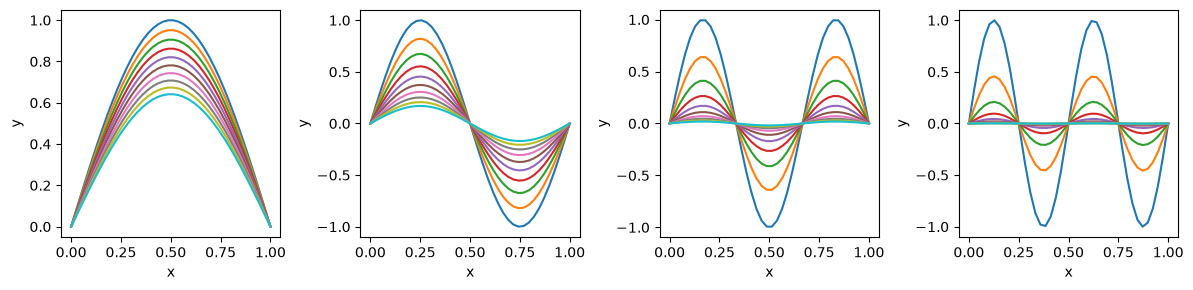

In [31]:
fig, ax = plt.subplots(1, 4, figsize=(12, 3))
for i, n in enumerate([1, 2, 3, 4]):
    L = 1
    N = 40
    x = np.linspace(0, L, N)
    y0 = np.sin(n*x*np.pi/L)
    D = 0.05  # diffusion constant
    dt = 0.1 # time step
    ts = 1.   # time for solution
    t = np.arange(0, ts, dt)
    y = odeint(diff1D, y0, t, (x, D))
    plt.subplot(1, 4, i+1)
    plt.plot(x, y.T)
    plt.xlabel("x"); plt.ylabel("y");
plt.tight_layout()

## 2. Wave Equation

While the wave equation with Dirichlet boundary condition simulates oscillation of a string, that with Neumann condition

$$ \left.\frac{\partial y(x,t)}{\partial x}\right|_{x_0}=\left.\frac{\partial y(x,t)}{\partial x}\right|_{x_N}=0 $$

can simulate water wave.

1) Implement a wave equation with a decay term

$$ \frac{\partial^2 u}{\partial t^2} = c^2 \frac{\partial^2 u}{\partial x^2} - d \frac{\partial u}{\partial t} $$

with the Neumann boundary conditions and see how the wave ripples.

In [3]:
def wave1D(y, t, x, c, d, inp=None):
    """1D wave equaiton with constant boundary
    y: state vector hstack(u, v)
    t: time
    x: positions
    c: wave speed
    input: function(y,x,t)"""
    n = int(len(y)/2)
    u, v = y[:n], y[n:]
    dx = x[1] - x[0]
    # finite different approximation
    d2udx2 = (u[:-2] -2*u[1:-1] + u[2:])/dx**2
    d2udx2 = np.hstack((2 * (u[1] - u[0]) / dx**2, d2udx2, 2 * (u[-2] - u[-1]) / dx**2))  # neumann boundary condition
    # d2udx2 = np.hstack((0, d2udx2, 0))  # add 0 to both ends
    if inp == None:
        return np.hstack((v, c**2*d2udx2 - d*v))
    else:
        return np.hstack((v, c**2*d2udx2 - d*v + inp(y, x, t)))

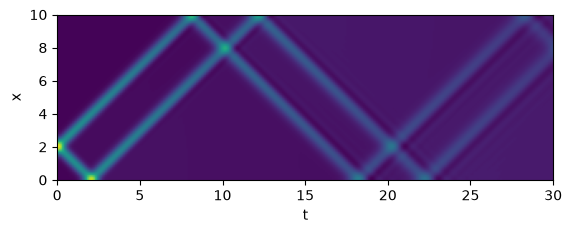

In [18]:
Lx = 10
N = 100
x = np.linspace(0, Lx, N+1)
c = 1.  # wave speed
d = 0.1
ts = 30
dt = 0.1
t = np.arange(0, ts, dt)
y0 = np.zeros(2*(N+1))  # initial condition
# y0[20:30] = 1
y0[:N+1] = np.exp(-(x - 2)**2/0.2)
y = odeint(wave1D, y0, t, (x, c, d))
# y = odeint(wave1D, y0, t, (x, c, d, pulse))
# plot in space and time
# show only first dimension
plt.imshow(y[:,:N+1].T, origin='lower', extent=(0, ts, 0, Lx))
plt.xlabel("t"); plt.ylabel("x");

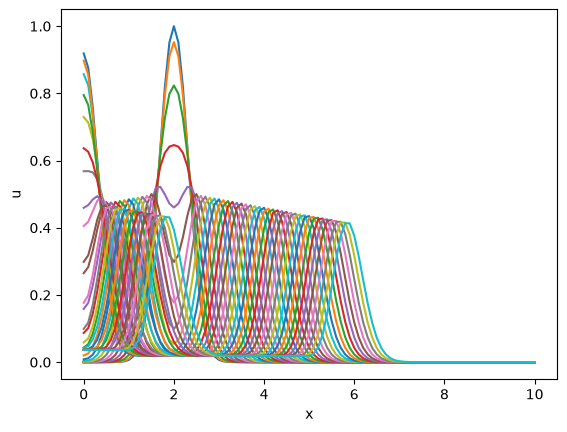

In [19]:
#evolution in spatial pattern
plt.plot(x, y[:40:,:N+1].T)  # only first dimension
plt.xlabel("x"); plt.ylabel("u");

2) See how the waves vary with the initial condition or stimulum.

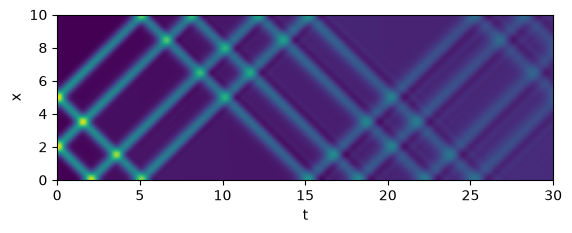

In [21]:
Lx = 10
N = 100
x = np.linspace(0, Lx, N+1)
c = 1.  # wave speed
d = 0.1
ts = 30
dt = 0.1
t = np.arange(0, ts, dt)
y0 = np.zeros(2*(N+1))  # initial condition
# y0[20:30] = 1
y0[:N+1] = np.exp(-(x - 2)**2/0.2) + np.exp(-(x - 5)**2/0.2)
y = odeint(wave1D, y0, t, (x, c, d))
# y = odeint(wave1D, y0, t, (x, c, d, pulse))
# plot in space and time
# show only first dimension
plt.imshow(y[:,:N+1].T, origin='lower', extent=(0, ts, 0, Lx))
plt.xlabel("t"); plt.ylabel("x");

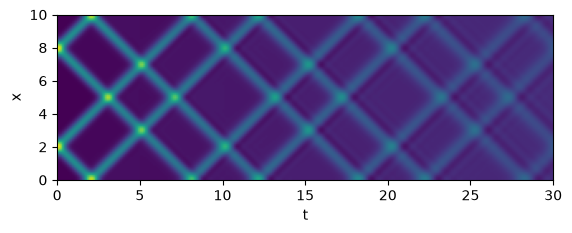

In [29]:
y0 = np.zeros(2*(N+1))  # initial condition
# y0[20:30] = 1
y0[:N+1] = np.exp(-(x - 2)**2/0.2) + np.exp(-(x - 8)**2/0.2)
y = odeint(wave1D, y0, t, (x, c, d))
# y = odeint(wave1D, y0, t, (x, c, d, pulse))
# plot in space and time
# show only first dimension
plt.imshow(y[:,:N+1].T, origin='lower', extent=(0, ts, 0, Lx))
plt.xlabel("t"); plt.ylabel("x");

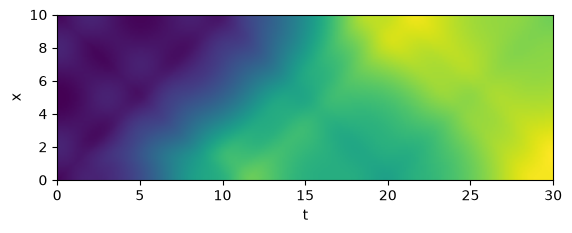

In [35]:
def pulse(y, x, t):
    """1 for 1<x<2 at 1<t<2"""
    return (1<x)*(x<2)*(1<t)*(t<10)*1.

y0 = np.zeros(2*(N+1))  # initial condition
# y0[20:30] = 1
y0[:N+1] = np.exp(-(x - 2)**2/3) + np.exp(-(x - 8)**2/3)
# y = odeint(wave1D, y0, t, (x, c, d))
y = odeint(wave1D, y0, t, (x, c, d, pulse))
# plot in space and time
# show only first dimension
plt.imshow(y[:,:N+1].T, origin='lower', extent=(0, ts, 0, Lx))
# plt.imshow(y[:,N+1:].T, origin='lower', extent=(0, ts, 0, Lx))
plt.xlabel("t"); plt.ylabel("x");

## Optional: Wave equation in 2D
Try simulating waves in a 2D space with a cyclic boundary condition.